In [56]:
# %pip install torch torchvision numpy matplotlib scikit-learn

# Read file

In [57]:
import gzip
import numpy as np
import matplotlib.pyplot as plt

In [58]:
image_file = "/Users/kellyt/Documents/ml/HW8/MNISTdata/train-images-idx3-ubyte.gz"
label_file = "/Users/kellyt/Documents/ml/HW8/MNISTdata/train-labels-idx1-ubyte.gz"

with gzip.open(image_file, 'rb') as f:
    images = np.frombuffer(f.read(), dtype=np.uint8, offset=16)

with gzip.open(label_file, 'rb') as f:
    labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8)

In [59]:
import gzip
import struct

with gzip.open(image_file, 'rb') as f:
    magic, num_images, rows, cols = struct.unpack(
        '>IIII', f.read(16)
    )

print("Magic number:", magic)
print("Number of images:", num_images)
print("Number of rows:", rows)
print("Number of columns:", cols)

Magic number: 2051
Number of images: 60000
Number of rows: 28
Number of columns: 28


In [60]:
images = images.reshape(-1, 28, 28) #28x28 is the original format

print(images.shape)
print(labels.shape)

(60000, 28, 28)
(60000,)


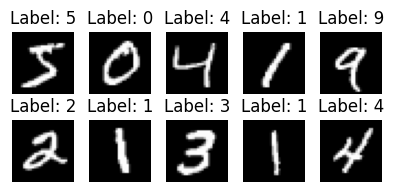

In [61]:
plt.figure(figsize=(4, 2))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(f"Label: {labels[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Data Preparation

In [62]:
# Flatten image
X = images.reshape(images.shape[0], -1)
y = labels

print(X.shape) # 784 cuz 28x28
print(y.shape)

(60000, 784)
(60000,)


In [63]:
X = X.astype('float32') / 255.0 # pixel values range from 0 to 255
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [64]:
print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Pixel range:", X.min(), "to", X.max())

Feature matrix: (60000, 784)
Labels: (60000,)
Pixel range: 0.0 to 1.0


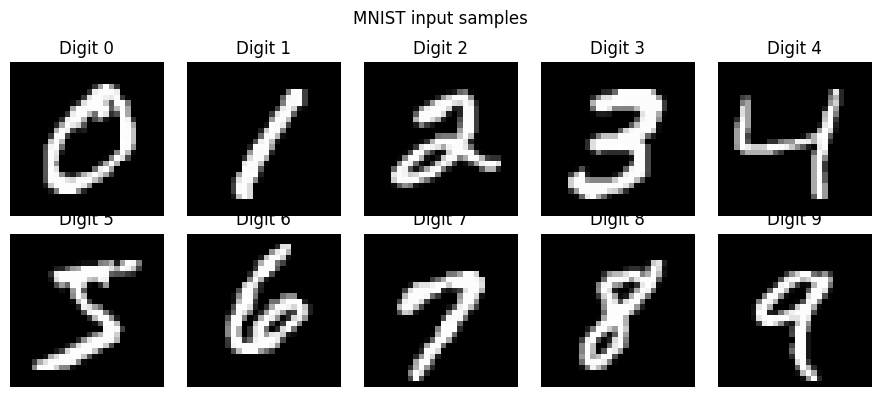

In [65]:
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for digit, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == digit)[0]
    ax.imshow(X[idx].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Digit {digit}')
    ax.axis('off')
plt.suptitle('MNIST input samples')
plt.tight_layout()
plt.show()

# Deep Neural Network on MNIST Data

In [66]:
import gzip
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print('PyTorch version:', torch.__version__)
print('Device:', device)

PyTorch version: 2.8.0
Device: mps


## Train and split data

In [67]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train)),
    batch_size=256, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_val)),
    batch_size=512, shuffle=False, num_workers=0
)
print('Training:', X_train.shape)
print('Validation:', X_val.shape)

Training: (48000, 784)
Validation: (12000, 784)


## Build deep autoencoder

In [68]:
class DeepAutoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 64), nn.ReLU(),
            nn.Linear(64, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.ReLU(),
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon

model = DeepAutoencoder(latent_dim=2).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(model)

DeepAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=512, bias=True)
    (5): ReLU()
    (6): Linear(in_features=512, out_features=784, bias=True)
    (7): Sigmoid()
  )
)


## Train autoencoder

In [69]:
EPOCHS = 10
train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for (batch_x,) in train_loader:
        batch_x = batch_x.to(device)
        optimizer.zero_grad()
        x_recon = model(batch_x)
        loss = criterion(x_recon, batch_x)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * batch_x.size(0)
    train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(train_loss)

    model.eval()
    running_val_loss = 0.0
    with torch.inference_mode():
        for (batch_x,) in val_loader:
            batch_x = batch_x.to(device)
            x_recon = model(batch_x)
            loss = criterion(x_recon, batch_x)
            running_val_loss += loss.item() * batch_x.size(0)
    val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(val_loss)

    print(f'Epoch {epoch + 1:02d}/{EPOCHS} | '
          f'train MSE: {train_loss:.5f} | val MSE: {val_loss:.5f}')

Epoch 01/10 | train MSE: 0.06858 | val MSE: 0.05316
Epoch 02/10 | train MSE: 0.04978 | val MSE: 0.04653
Epoch 03/10 | train MSE: 0.04527 | val MSE: 0.04384
Epoch 04/10 | train MSE: 0.04311 | val MSE: 0.04224
Epoch 05/10 | train MSE: 0.04189 | val MSE: 0.04189
Epoch 06/10 | train MSE: 0.04105 | val MSE: 0.04013
Epoch 07/10 | train MSE: 0.04019 | val MSE: 0.03994
Epoch 08/10 | train MSE: 0.03961 | val MSE: 0.03912
Epoch 09/10 | train MSE: 0.03903 | val MSE: 0.03866
Epoch 10/10 | train MSE: 0.03865 | val MSE: 0.03848


# Plot learning curve

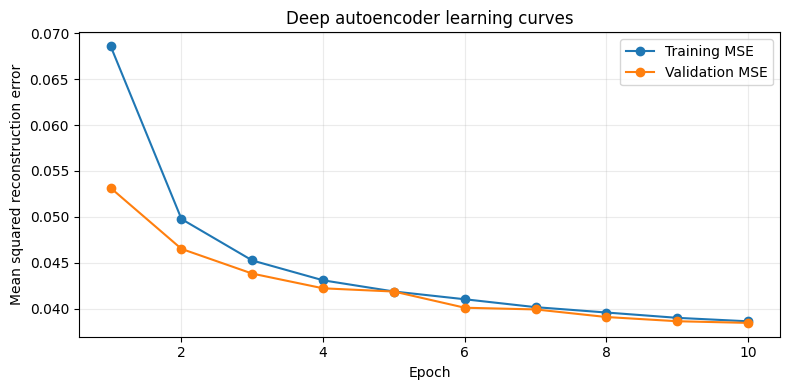

In [70]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_losses, marker='o', label='Training MSE')
plt.plot(range(1, EPOCHS + 1), val_losses, marker='o', label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('Mean squared reconstruction error')
plt.title('Deep autoencoder learning curves')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [71]:
model.eval()
Z_batches = []
reconstructed_batches = []
with torch.inference_mode():
    for (batch_x,) in val_loader:
        batch_x = batch_x.to(device)
        Z_batches.append(model.encoder(batch_x).cpu().numpy())
        reconstructed_batches.append(model(batch_x).cpu().numpy())

Z_val = np.concatenate(Z_batches, axis=0)
X_recon = np.concatenate(reconstructed_batches, axis=0)

print('Original validation images:', X_val.shape)
print('Learned 2D code:', Z_val.shape)
print('Autoencoder reconstructions:', X_recon.shape)
print('Autoencoder validation MSE:', np.mean((X_val - X_recon) ** 2))

Original validation images: (12000, 784)
Learned 2D code: (12000, 2)
Autoencoder reconstructions: (12000, 784)
Autoencoder validation MSE: 0.038480297


PCA code shape: (12000, 2)
PCA validation MSE: 0.055805087
Autoencoder validation MSE: 0.038480297


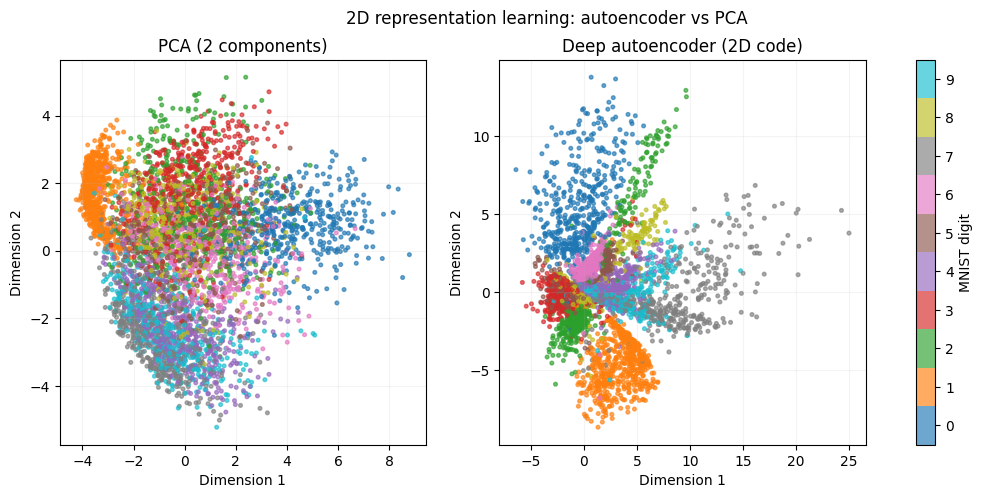

In [72]:
pca = PCA(n_components=2)
pca.fit(X_train)
Z_pca = pca.transform(X_val)
X_pca_recon = pca.inverse_transform(Z_pca)

print('PCA code shape:', Z_pca.shape)
print('PCA validation MSE:', np.mean((X_val - X_pca_recon) ** 2))
print('Autoencoder validation MSE:', np.mean((X_val - X_recon) ** 2))

rng = np.random.default_rng(SEED)
plot_idx = rng.choice(len(X_val), size=min(5000, len(X_val)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, codes, title in zip(
    axes,
    [Z_pca, Z_val],
    ['PCA (2 components)', 'Deep autoencoder (2D code)']
):
    points = ax.scatter(
        codes[plot_idx, 0], codes[plot_idx, 1],
        c=y_val[plot_idx], cmap='tab10',
        vmin=-0.5, vmax=9.5, s=7, alpha=0.65, rasterized=True
    )
    ax.set_xlabel('Dimension 1')
    ax.set_ylabel('Dimension 2')
    ax.set_title(title)
    ax.grid(alpha=0.15)

fig.colorbar(points, ax=axes, ticks=list(range(10)), label='MNIST digit')
fig.suptitle('2D representation learning: autoencoder vs PCA')
plt.show()

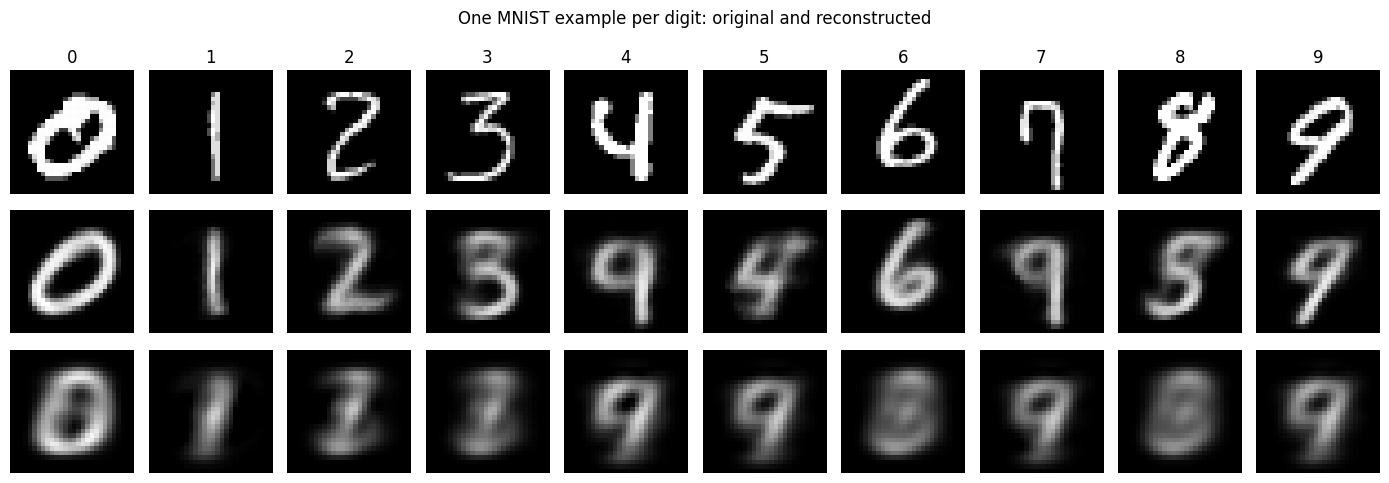

In [73]:
# Select one validation example for each of the 10 digits.
show_idx = [np.flatnonzero(y_val == digit)[0] for digit in range(10)]
rows = [
    ('Original', X_val),
    ('Autoencoder', X_recon),
    ('PCA (2D)', X_pca_recon)
]

fig, axes = plt.subplots(3, 10, figsize=(14, 5))
for row_idx, (row_title, data) in enumerate(rows):
    for col_idx, idx in enumerate(show_idx):
        axes[row_idx, col_idx].imshow(
            np.clip(data[idx].reshape(28, 28), 0, 1),
            cmap='gray', vmin=0, vmax=1
        )
        axes[row_idx, col_idx].axis('off')
        if row_idx == 0:
            axes[row_idx, col_idx].set_title(str(y_val[idx]))
    axes[row_idx, 0].set_ylabel(row_title, rotation=90, size=10, labelpad=13)
plt.suptitle('One MNIST example per digit: original and reconstructed')
plt.tight_layout()
plt.show()